# M3a: exactly one chgpt, α = 0.5

In [ ]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/M1a_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)

    progress_handler = logging.FileHandler('logs/M1a_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        if self.completed_tasks % max(1, self.total_tasks // 5) == 0 or self.completed_tasks == 1:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    κ = np.sqrt(1.0) # np.sqrt(15) originally
    α = 0.5
    σ_l_arr = κ * np.sqrt(δ) * np.ones(L)
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p)
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    ε = np.random.uniform(0, 1, size=(n, ))



    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = np.array(jax.vmap(WERM.model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε))
    # y_standardized = y
    # print(f"y std: {np.std(y_standardized):.4f}, mean: {np.mean(y_standardized):.4f}")
    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators for all configured methods ---
    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    for method_name, method_func_info in method_configs.items():
        try:
            print(f"Running {method_name} on params: ", params)
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'GLMBSA':
                # cp = np.asarray(WERM.comparison.glm_bsa(X, y_standardized, delta = 0.1, kmax=len(fractional_chgpt_locations), is_exact=True))
                delta_fraction = 1/20
                cp = np.array(WERM.comparison.glm_bsa2(X_scaled, y.reshape((n, 1)), 
                                                       kmax=len(fractional_chgpt_locations), c1=0.18, 
                                                       m1 = None, delta = delta_fraction, exact=True))
                # Convert change points to 0-based indices, they are originally 1-based
                cp = cp - 1 # Convert to 0-based indexing
                # Remove endpoints
                cp = cp[(cp > 0) & (cp < n-1)] # Remove endpoints
                print("BSA cp: ", cp)
            elif method_name == 'WERM-CV':
                delta_fraction = 1/20
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                # Run cross-validation to find the best regularisation penalty parameter
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""

                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_
                    )

                # Perform cross-validation to find the best gamma
                # best_l1_reg, best_model_output = WERM.estimators.chgpt_k_fold_cv(
                #     f=WERM_l1_reg_paramCV,
                #     X=X,
                #     y=y,
                #     gamma_candidates=[1e-4, 1e-3, 1e-2],
                #     M_scorer=M_scorer,
                #     P_scorer=None,
                #     k=2,
                #     n_jobs=1
                # )

                # Fit OLS via least squares
                # beta_hat, _, _, _ = np.linalg.lstsq(X_scaled, y, rcond=None)

                # Compute residuals and estimate sigma
                # residuals = y - X_scaled.dot(beta_hat)
                # Unbiased estimator of sigma
                # sigma_hat = np.sqrt(np.sum(residuals**2) / (n - p - 1))
                # sigma_hat = np.median(np.abs(residuals - np.median(residuals))) / 0.6745 # More robust estimate of scale
                # sigma_hat=noise_std # Use the provided noise_std directly

                # Universal lambda
                # lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) + np.log(2*p)/n
                lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) 

                # λ = c1 * ( np.sqrt(2 * np.log(2*p) / n) + np.log(2*p) / n


                # Best setting is κ=1.0, C=10, lambda_hat the shorter version
                # best_l1_reg = 3.25e-3
                C=10
                # C=16
                best_l1_reg = C * n * lambda_hat
                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0.0,
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=True, P_func=P_func
                )
            elif method_name == 'WERM-unp':
                # Placeholder for WERM-unp method
                # This calls WERM.estimators.weighted_erm with P_func=None (no penalty)
                delta_fraction = 1/20
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                # gamma_candidates = np.array([1e-1, 1e-0, 1e1])
                # best_gamma, cp = WERM.estimators.weighted_erm_extended_penalizedCV(
                #     X, y, M, L, 
                #     Delta_n(n), gamma_candidates=gamma_candidates,
                #     brute_force=False, M_scorer=M_scorer,
                #     P_scorer=None, num_folds=2, n_jobs=2
                # )
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=True, 
                )
            elif method_name == 'WERM-fixed':
                # Placeholder for WERM-fixed method (e.g., with a fixed gamma)
                # This calls WERM.estimators.weighted_erm with a fixed penalty
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )

            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time

            # Handle Hausdorff distance calculation based on the method
            if method_name == 'DCDP' or method_name == 'DPDU': # DCDP and DPDU use closest_point_distance since they don't return a fixed number of changepoints
                if len(cp) > 0:
                    trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.closest_point_distance(cp, true_chgpts)
                else:
                    trial_results[f'haus_{method_name}'] = np.nan
            else: # Other methods use hausdorff
                trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp, true_chgpts)

            trial_results[f'size_{method_name}'] = len(cp[cp != -1])
            trial_results[f'chgpts_{method_name}'] = cp.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}")
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting Changepoint Detection Simulation with flexible methods and enhanced logging")
main_logger.info("=" * 60)

# Simulation Parameters
p = 200
L = 2
noise_std = np.sqrt(0.6) # Not used in logistic model
# δ_list = np.arange(1.0, 6.0, 1.0)
# δ_list = np.arange(1.0, 7.0, 1.0) #good
δ_list = np.arange(1.0, 8.0, 1.0)
num_trials = 30
# fractional_chgpt_locations = np.array([1/3, 8/15])
fractional_chgpt_locations = np.array([1/3])
# n_jobs = -1 # Use all available CPU cores
n_jobs = 45
# n_jobs = 3

# --- Set the covariance matrix for the features ---
r = 0.0
Sigma = np.eye(p)
for i_cov in range(p):
    for j_cov in range(p):
        if i_cov != j_cov:
            Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))            # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                                # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                     # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)      

# Sigma = sample_corr(p, df=10, seed=random_seed)  # Sample a random correlation matrix

# --- Define Methods to be Evaluated ---
# This is the central list you can modify
methods_to_evaluate = [
    {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'color': '#EE3377', 'marker': '^', 'linestyle': ':'},
    {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'color': '#CC3311', 'marker': 'v', 'linestyle': '-'},
    # {'name': 'WERM-unp', 'label': r'\textbf{WERM-unp}', 'color': '#009988', 'marker': '<', 'linestyle': '--'},
    # {'name': 'WERM-fixed', 'label': r'\textbf{WERM-fixed}', 'color': '#BBBBBB', 'marker': '>', 'linestyle': '-.'},
]

# Removed the hardcoded check for exactly 4 methods.
# if len(methods_to_evaluate) != 4:
#     raise ValueError("The 'methods_to_evaluate' list must contain exactly 4 methods.")

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []


# Logistic loss function
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
M_scorer = M

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-4, 1, 8)

# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 60)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

single_trial_estimate = 30.0 * len(methods_to_evaluate)
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 60)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates,
            method_configs=method_configs
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 60)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 60)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}")
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})
main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    # Updated ncol to dynamically adjust to the number of methods + True Size
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals}',
                     fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    # Updated ncol to dynamically adjust to the number of methods + True Size
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                     fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                               for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                        edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
# Pass the names of the methods for histogram plotting
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/M3a_{method_names_for_filename}_results_p{p}_L{L}_r{r}_noisestd{noise_std}_{'_'.join(map(str, map(int, δ_list)))}_.pkl"
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate # Save the method configurations
        }
    }, f)

In [ ]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})
main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.3))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    # Updated ncol to dynamically adjust to the number of methods + True Size
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals}',
                     fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    # Updated ncol to dynamically adjust to the number of methods + True Size
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                     fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                               for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                        edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
# Pass the names of the methods for histogram plotting
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/M3a_{method_names_for_filename}_results_p{p}_L{L}_r{r}_noisestd{noise_std}_{'_'.join(map(str, map(int, δ_list)))}_.pkl"
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate # Save the method configurations
        }
    }, f)

## Load and plot

Removing 110 matplotlib modules...
Successfully set backend to: pgf
main_logger not defined, skipping logging.
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Data loaded/dummy data created for plotting.
DEBUG: Original δ_list: [1. 2. 3. 4. 5. 6. 7.]
DEBUG: Filtered δ_list (>= 1.5): [2. 3. 4. 5. 6. 7.]
DEBUG: Method names available: ['GLMBSA', 'WERM-CV']
DEBUG: First few haus results (filtered): No
Creating publication-ready plots...

--- Asymmetric Error Bars Plots ---
1. Asymmetric error bars (publication style) - All metrics


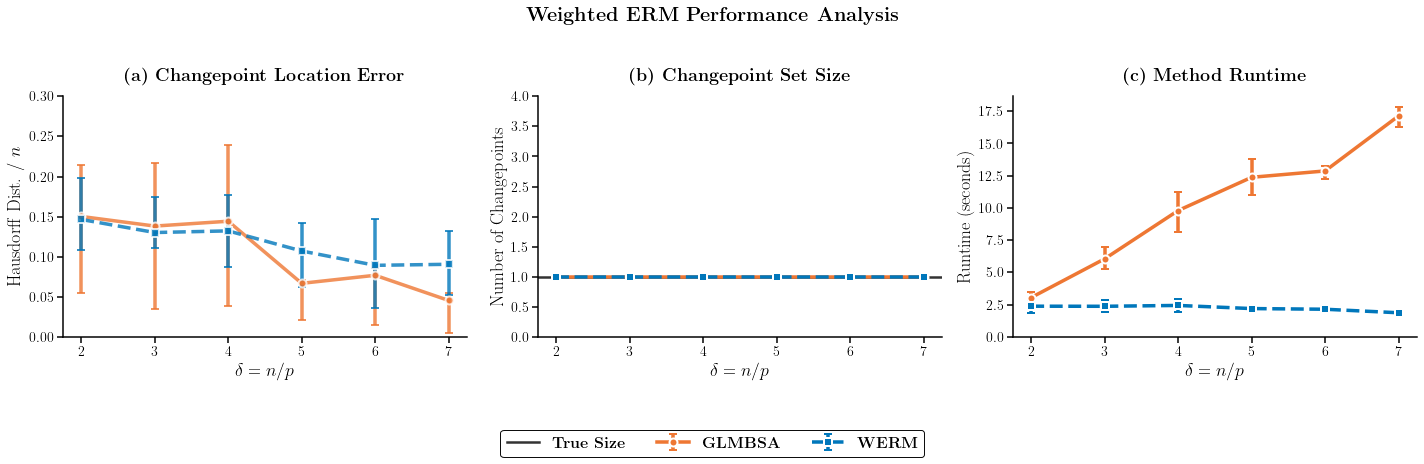

1. Asymmetric error bars (publication style) - location


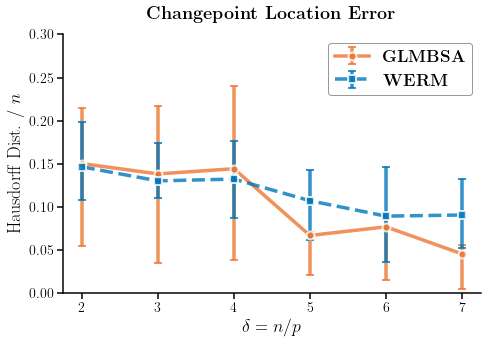

1. Asymmetric error bars (publication style) - size


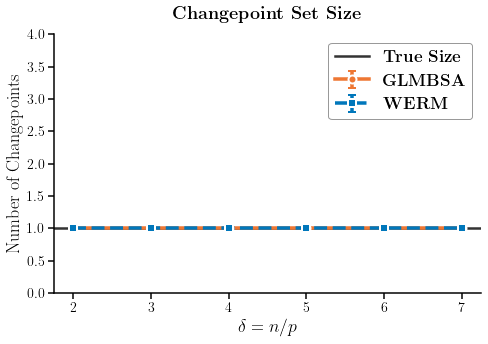

1. Asymmetric error bars (publication style) - runtime


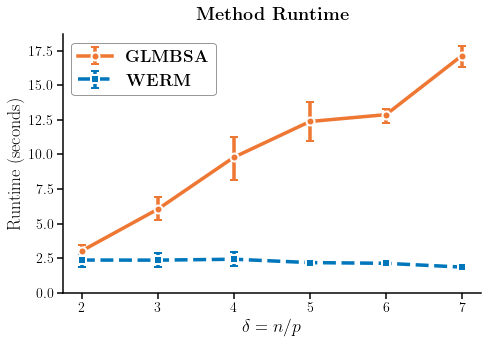


--- Confidence Bands Plots ---
2. Confidence bands (publication style)...


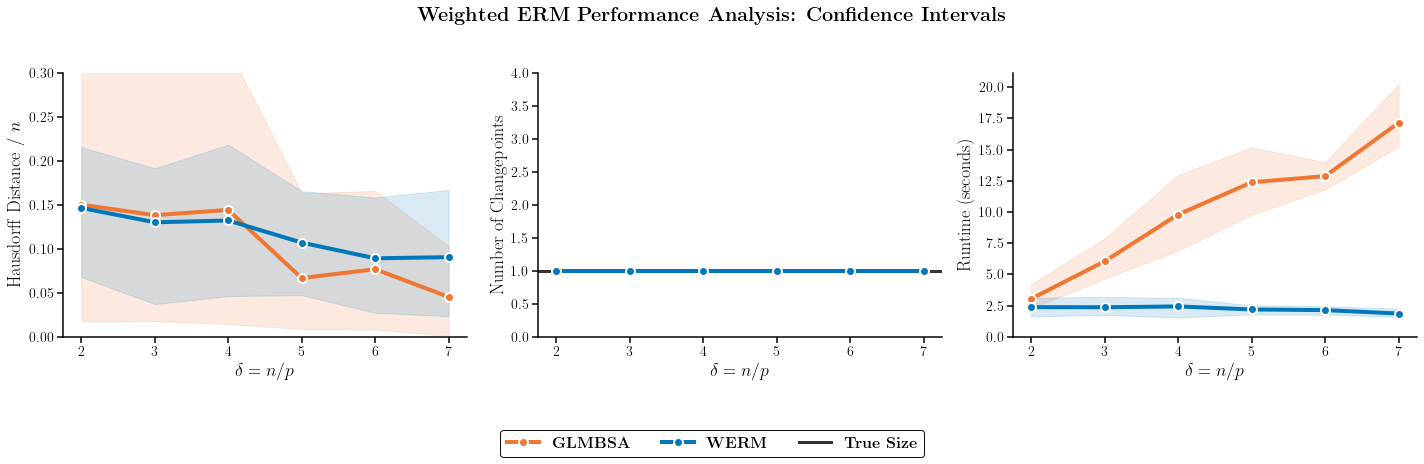


--- Box Plots ---
3. Box plots (publication style) - All metrics...


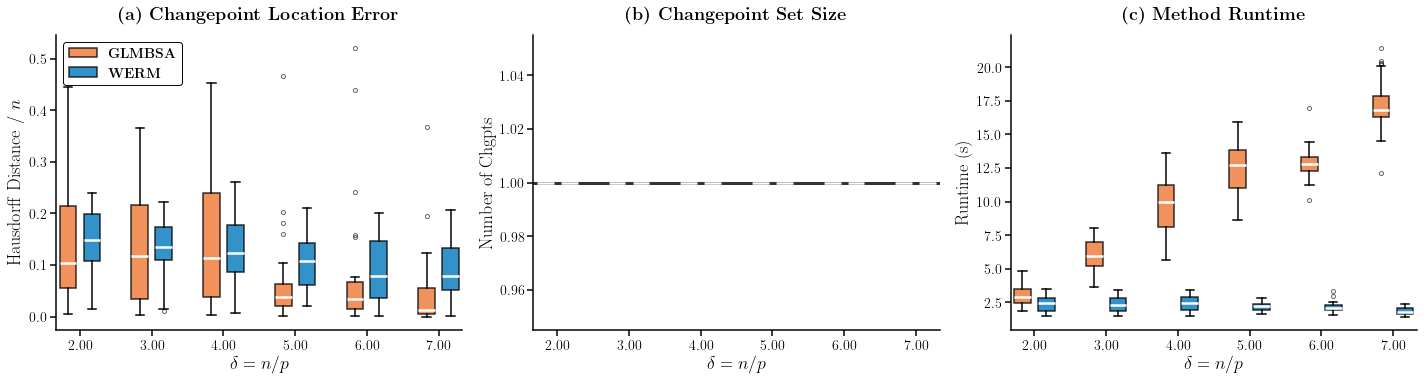

3.1. Separate box plot for location (publication style)...
3.2. Separate box plot for runtime (publication style)...

--- Changepoint Histograms ---
4. Enhanced changepoint histograms (publication style)...


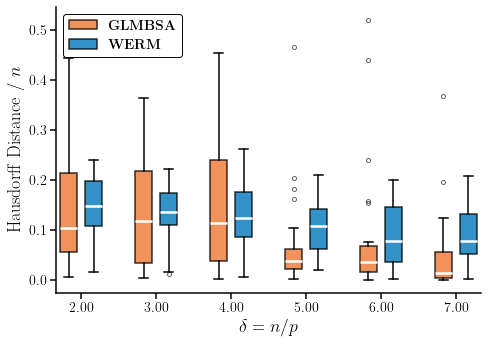

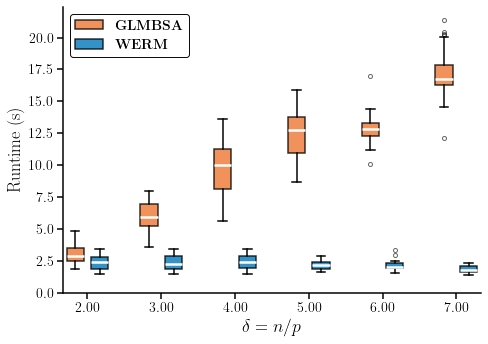

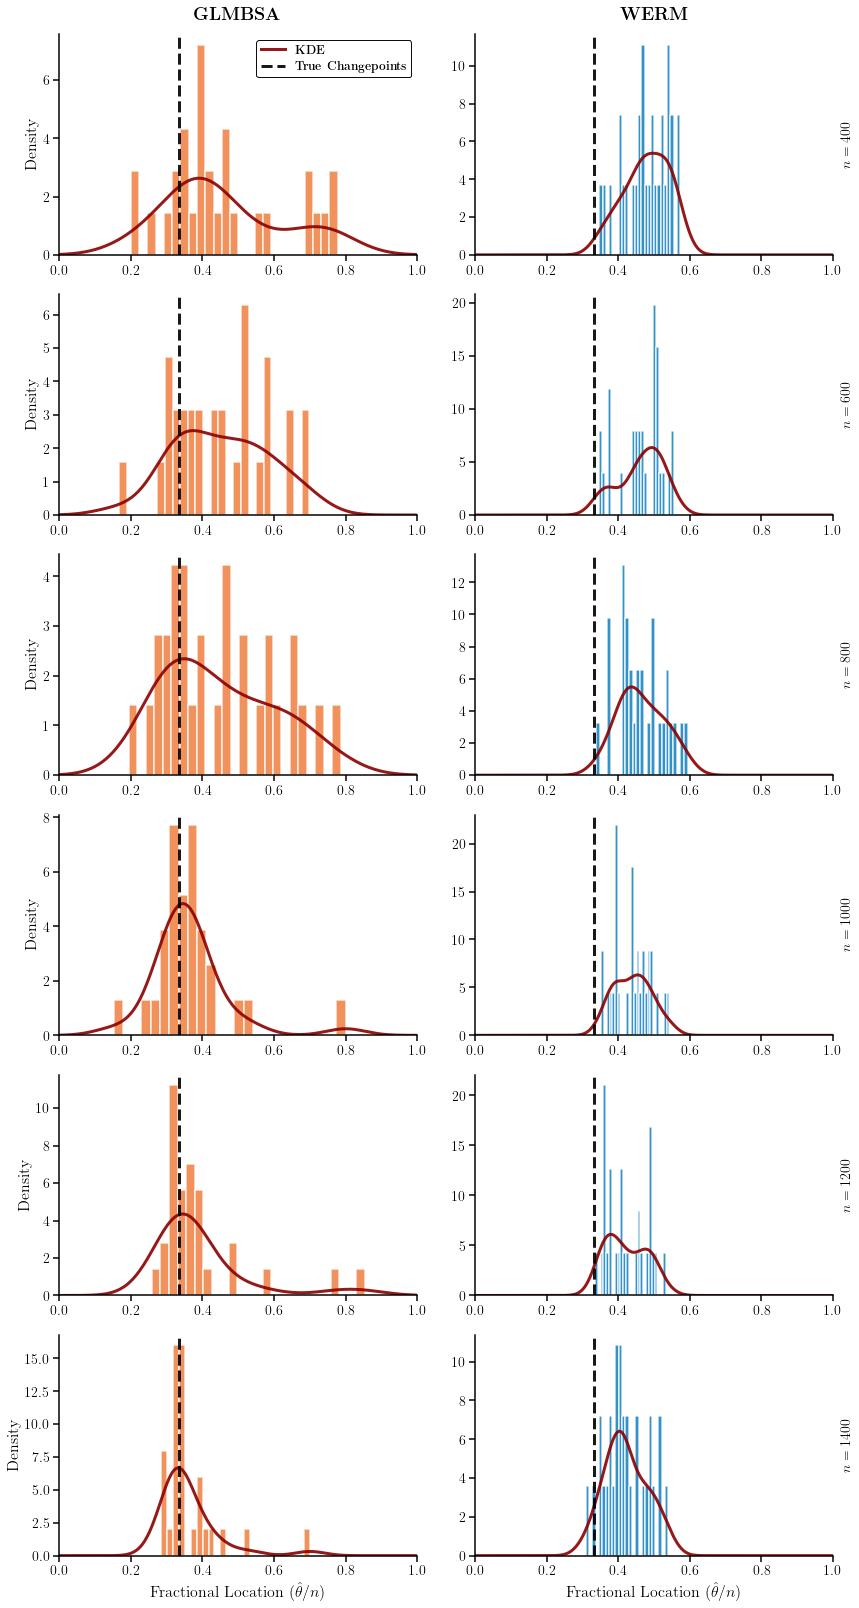

Publication-ready plotting completed in 3.34 seconds


In [4]:
# -----------------------------------------------------------------------------
# 5. Publication-Ready Enhanced Plotting Results
# -----------------------------------------------------------------------------
import sys
import numpy as np # Make sure numpy is imported
import time # Make sure time is imported
import matplotlib # Make sure matplotlib is imported
import gc
from scipy.stats import gaussian_kde # For KDE in histograms
import matplotlib.pyplot as plt
import pickle

methods_to_evaluate = [
    {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'color': '#EE3377', 'marker': '^', 'linestyle': ':'},
    {'name': 'WERM-CV', 'label': r'\textbf{WERM}', 'color': '#CC3311', 'marker': 'v', 'linestyle': '-'},
    # {'name': 'WERM-unp', 'label': r'\textbf{WERM-unp}', 'color': '#009988', 'marker': '<', 'linestyle': '--'},
    # {'name': 'WERM-fixed', 'label': r'\textbf{WERM-fixed}', 'color': '#BBBBBB', 'marker': '>', 'linestyle': '-.'},
]

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',  # or 'xelatex', 'lualatex'
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,      # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 16,     # Larger axis labels
    'axes.titlesize': 18,     # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': True,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 72,          # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Assuming `main_logger` is defined elsewhere in your script or you can remove this line
try:
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

# RECOMMENDED: Most aesthetic AND colorblind-friendly palette
# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']

# Use the most aesthetic palette
PAL = TOL_VIBRANT
# random.shuffle(PAL)

print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data and set up global parameters (moved from end to top for clarity) ---
# This part assumes you have a filename to load from, or you'll need to define
# `results`, `params`, `p`, `L`, `noise_std`, `δ_list`, `fractional_chgpt_locations`,
# `n_jobs`, `methods_to_evaluate`, `random_seed` directly or load them differently.

# Example of how to load the data (adjust filename as needed)
# You need to ensure the `results` dictionary and `params` are populated
# before calling the plotting functions.
try:
    # This filename needs to match your saved results
    # For the example, I'll use the one provided in the original code.
    # Replace with your actual filename if different.
    _example_filename = 'results/M3a_GLMBSA_WERM-CV_results_p200_L2_r0.0_noisestd0.7745966692414834_1_2_3_4_5_6_7_.pkl'
    with open(_example_filename, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    δ_list = params['δ_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    n_jobs = params['n_jobs']
    # methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', None)

    # Extract method names for plotting
    method_names_list = [method['name'] for method in methods_to_evaluate]

except FileNotFoundError:
    print(f"Warning: Results file '{_example_filename}' not found. Please ensure your results are saved or define `results` and `params` directly for plotting.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 100
    L = 3
    noise_std = 0.5
    δ_list = np.array([1, 1.5, 2, 3, 4, 5, 6]) # Added 1.5 for demonstration
    fractional_chgpt_locations = [0.2, 0.5, 0.8]
    num_trials = 10
    n_jobs = 1
    # Dummy methods_to_evaluate based on original code's 'simple', 'ext', 'elbow', 'kneedle'
    methods_to_evaluate = [
        {'name': 'simple', 'label': r'\textbf{Full Prior}'},
        {'name': 'ext', 'label': r'\textbf{Location Prior}'},
        {'name': 'elbow', 'label': r'\textbf{Extended Elbow}'},
        {'name': 'kneedle', 'label': r'\textbf{Kneedle}'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Populate dummy results
    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            # Generate random data for dummy results
            if metric == 'chgpts':
                results[key] = []
                for delta_idx in range(len(δ_list)):
                    for _ in range(num_trials):
                        # Generate some dummy changepoints, vary by delta_idx
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        dummy_chgpts = np.random.rand(num_chgpts_detected) * (delta_idx / 5 + 0.5) # Example variation
                        results[key].append((delta_idx, dummy_chgpts * p * δ_list[delta_idx])) # Scale to n
            else:
                results[key] = np.random.rand(len(δ_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05

print("Data loaded/dummy data created for plotting.")

# Filter δ_list for plotting from δ = 1.5 and onwards
delta_start_index = np.where(δ_list >= 1.5)[0][0]
δ_list_filtered = δ_list[delta_start_index:]

# Filter results based on the new delta_list for line plots and all box plots
# Note: For 'chgpts' in plot_changepoint_histograms_publication, we will use the original `results` and `δ_list`
# and filter internally, as the stored indices relate to the original `δ_list`.
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > delta_start_index:
            results_filtered[key] = value[delta_start_index:, :]
        else:
            # Handle cases where slicing results in empty array due to delta_start_index
            # Create an empty array with the same number of columns as original data
            results_filtered[key] = np.empty((0, value.shape[1]))
    # 'chgpts' is NOT filtered here, as plot_changepoint_histograms_publication handles it directly from 'results'

# Debugging prints for verification
print(f"DEBUG: Original δ_list: {δ_list}")
print(f"DEBUG: Filtered δ_list (>= 1.5): {δ_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_simple', 'Not available')[:2]}")


# -----------------------------------------------------------------------------
# Option 1: Publication-Ready Asymmetric Error Bars
# -----------------------------------------------------------------------------

# Calculate percentiles for asymmetric error bars
def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles"""
    means = np.mean(data, axis=1)
    p25 = np.percentile(data, 25, axis=1)
    p75 = np.percentile(data, 75, axis=1)
    
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    
    if np.any(lower_errors < 0) or np.any(upper_errors < 0):
        std_errs = np.std(data, axis=1)
        return [std_errs, std_errs]
    
    return [lower_errors, upper_errors]

def plot_with_asymmetric_errors_publication(plot_type='all'):
    """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
    # Use filtered delta list and results
    current_δ_list = δ_list_filtered
    current_results = results_filtered

    if plot_type == 'all':
        fig, axs = plt.subplots(1, 3, figsize=(20, 6))
        fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
    else:
        fig, axs = plt.subplots(1, 1, figsize=(7, 5)) # Adjusted size for single plots
        
    # Use method_names_list from the loaded/generated params
    methods = method_names_list
    colors = PAL[:len(methods)] # Use as many colors as methods
    
    # Define markers and linestyles to match the number of methods
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
    
    labels = [method['label'] for method in methods_to_evaluate] # Use labels from methods_to_evaluate
    
    # Hausdorff Distance Plot
    if plot_type == 'all' or plot_type == 'location':
        if plot_type == 'all': ax = axs[0]
        elif plot_type == 'location': ax = axs
        for i, method_name in enumerate(methods):
            data = current_results[f'haus_{method_name}']
            if data.size == 0: # Handle empty data after filtering
                print(f"Warning: No data for haus_{method_name} after filtering for delta >= 1.5. Skipping plot.")
                continue
            means = np.mean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(current_δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white',
                        alpha=0.8)
        
        ax.set_ylim((0, 0.3))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Hausdorff Dist. / $n$', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
        else: # For individual plot
            ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15)
        
        # Cleaner x-axis with fewer ticks
        ax.set_xticks(current_δ_list[::max(1, len(current_δ_list) // 5)])  # Show 5 ticks max
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'location': # For individual location plot, add legend
            ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
            
    # Changepoint Set Size Plot
    if plot_type == 'all' or plot_type == 'size':
        if plot_type == 'all': ax = axs[1]
        elif plot_type == 'size': ax = axs

        for i, method_name in enumerate(methods):
            data = current_results[f'size_{method_name}']
            if data.size == 0: # Handle empty data after filtering
                print(f"Warning: No data for size_{method_name} after filtering for delta >= 1.5. Skipping plot.")
                continue
            means = np.mean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(current_δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                   linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        ax.set_ylim((0, L + 2))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Number of Changepoints', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
        else: # For individual plot
            ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15)
        
        ax.set_xticks(current_δ_list[::max(1, len(current_δ_list) // 5)])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'size': # For individual size plot, add legend
            ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
            
    # Runtime Plot
    if plot_type == 'all' or plot_type == 'runtime':
        if plot_type == 'all': ax = axs[2]
        elif plot_type == 'runtime': ax = axs
        for i, method_name in enumerate(methods):
            data = current_results[f'runtime_{method_name}']
            if data.size == 0: # Handle empty data after filtering
                print(f"Warning: No data for runtime_{method_name} after filtering for delta >= 1.5. Skipping plot.")
                continue
            means = np.mean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(current_δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        ax.set_ylim(bottom=0)
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
        else: # For individual plot
            ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15)
        
        ax.set_xticks(current_δ_list[::max(1, len(current_δ_list) // 5)])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
        if plot_type == 'runtime': # For individual runtime plot, add legend
            ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
            
    if plot_type == 'all':
        # Single legend for all subplots
        handles, labels_leg = axs[1].get_legend_handles_labels()
        fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                   ncol=len(methods)+1, fontsize=16, frameon=True,
                   edgecolor='black', framealpha=0.95)
        plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    else:
        fig.tight_layout()
            
    return fig, axs

# -----------------------------------------------------------------------------
# Option 2: Publication-Ready Confidence Bands
# -----------------------------------------------------------------------------
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)
    
    # Use filtered delta list and results
    current_δ_list = δ_list_filtered
    current_results = results_filtered

    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]
    
    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        
        for method_idx, method_name in enumerate(methods):
            data = current_results[f'{metric}_{method_name}']
            if data.size == 0: # Handle empty data after filtering
                print(f"Warning: No data for {metric}_{method_name} after filtering for delta >= 1.5. Skipping plot.")
                continue
            means = np.mean(data, axis=1)
            
            # Calculate confidence intervals (10th and 90th percentiles)
            p10 = np.percentile(data, 10, axis=1)
            p90 = np.percentile(data, 90, axis=1)
            
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)
            
            # Plot confidence band first (so it's behind the line)
            ax.fill_between(current_δ_list, p10, p90, color=colors[method_idx],
                            alpha=0.15, zorder=1)
            
            # Plot mean line with markers
            ax.plot(current_δ_list, means, color=colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
            
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)
            
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        # ax.set_title(title, fontsize=18, pad=15)
        
        # Cleaner axes
        ax.set_xticks(current_δ_list[::max(1, len(current_δ_list) // 5)])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 3: Publication-Ready Box Plots (All three metrics)
# -----------------------------------------------------------------------------
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    # fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Distribution Comparison}',
    #              fontsize=20, y=0.98)
    
    # Use filtered delta list and results
    current_δ_list = δ_list_filtered
    current_results = results_filtered

    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Chgpts', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (s)', r'\textbf{(c) Method Runtime}')]
    
    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        
        # Create box plots for each delta value
        for delta_idx, delta in enumerate(current_δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            
            for method_idx, method_name in enumerate(methods):
                data = current_results[f'{metric}_{method_name}'][delta_idx, :]
                if data.size == 0: # Handle empty data after filtering
                    continue # Skip adding empty data to box_data
                box_data.append(data)
                box_positions.append(delta_idx * (len(methods) + 1) + method_idx) # Adjusted spacing
                box_colors.append(colors[method_idx])
            
            if not box_data: # If all data for this delta was empty, skip plotting
                continue

            # Create publication-ready box plots
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            
            # Color the boxes
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')
        
        # Set x-axis labels - only show every other delta for cleanliness
        # Adjust delta_positions calculation
        delta_positions = [i * (len(methods) + 1) + (len(methods) - 1) / 2.0 for i in range(len(current_δ_list))]
        ax.set_xticks(delta_positions[::max(1, len(current_δ_list) // 5)])  # Every other position
        ax.set_xticklabels([f'{d:.2f}' for d in current_δ_list[::max(1, len(current_δ_list) // 5)]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Add legend (only for first subplot)
        if ax_idx == 0:
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=labels[i])
                               for i in range(len(methods))]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                      frameon=True, edgecolor='black', framealpha=0.95)
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
        
        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

def plot_location_boxplots_publication():
    """
    Creates a separate box plot for changepoint location error.
    """
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # fig.suptitle(r'\textbf{Changepoint Location Error: Distribution Comparison}',
    #              fontsize=18, y=0.98)

    # Use filtered delta list and results
    current_δ_list = δ_list_filtered
    current_results = results_filtered
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]

    metric = 'haus'
    ylabel = r'Hausdorff Distance / $n$'
    
    # Create box plots for each delta value
    for delta_idx, delta in enumerate(current_δ_list):
        box_data = []
        box_positions = []
        box_colors = []
        
        for method_idx, method_name in enumerate(methods):
            data = current_results[f'{metric}_{method_name}'][delta_idx, :]
            if data.size == 0: # Handle empty data after filtering
                continue
            box_data.append(data)
            box_positions.append(delta_idx * (len(methods) + 1) + method_idx) # Adjusted spacing
            box_colors.append(colors[method_idx])
        
        if not box_data:
            continue

        # Create publication-ready box plots
        bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                        patch_artist=True, showfliers=True,
                        flierprops=dict(marker='o', markersize=4, alpha=0.6),
                        medianprops=dict(color='white', linewidth=2.5),
                        boxprops=dict(linewidth=1.5),
                        whiskerprops=dict(linewidth=1.5),
                        capprops=dict(linewidth=1.5))
        
        # Color the boxes
        for patch, color in zip(bp['boxes'], box_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.8)
            patch.set_edgecolor('black')
    
    # Set x-axis labels - only show every other delta for cleanliness
    delta_positions = [i * (len(methods) + 1) + (len(methods) - 1) / 2.0 for i in range(len(current_δ_list))]
    ax.set_xticks(delta_positions[::max(1, len(current_δ_list) // 5)])
    ax.set_xticklabels([f'{d:.2f}' for d in current_δ_list[::max(1, len(current_δ_list) // 5)]])
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    
    # Add legend
    legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                     alpha=0.8, edgecolor='black',
                                     linewidth=1.5, label=labels[i])
                       for i in range(len(methods))]
    ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
              frameon=True, edgecolor='black', framealpha=0.95, fancybox=True)
    
    # Clean axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    
    plt.tight_layout()
    return fig, ax

def plot_runtime_boxplots_publication():
    """
    Creates a separate box plot for runtime.
    """
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # fig.suptitle(r'\textbf{Method Runtime: Distribution Comparison}',
    #              fontsize=18, y=0.98)

    # Use filtered delta list and results
    current_δ_list = δ_list_filtered
    current_results = results_filtered
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]

    metric = 'runtime'
    ylabel = r'Runtime (s)'
    
    # Create box plots for each delta value
    for delta_idx, delta in enumerate(current_δ_list):
        box_data = []
        box_positions = []
        box_colors = []
        
        for method_idx, method_name in enumerate(methods):
            data = current_results[f'{metric}_{method_name}'][delta_idx, :]
            if data.size == 0: # Handle empty data after filtering
                continue
            box_data.append(data)
            box_positions.append(delta_idx * (len(methods) + 1) + method_idx) # Adjusted spacing
            box_colors.append(colors[method_idx])
        
        if not box_data:
            continue

        # Create publication-ready box plots
        bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                        patch_artist=True, showfliers=True,
                        flierprops=dict(marker='o', markersize=4, alpha=0.6),
                        medianprops=dict(color='white', linewidth=2.5),
                        boxprops=dict(linewidth=1.5),
                        whiskerprops=dict(linewidth=1.5),
                        capprops=dict(linewidth=1.5))
        
        # Color the boxes
        for patch, color in zip(bp['boxes'], box_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.8)
            patch.set_edgecolor('black')
    
    # Set x-axis labels - only show every other delta for cleanliness
    delta_positions = [i * (len(methods) + 1) + (len(methods) - 1) / 2.0 for i in range(len(current_δ_list))]
    ax.set_xticks(delta_positions[::max(1, len(current_δ_list) // 5)])
    ax.set_xticklabels([f'{d:.2f}' for d in current_δ_list[::max(1, len(current_δ_list) // 5)]])
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.set_ylim(bottom=0) # Runtime should start from 0
    
    # Add legend
    legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                     alpha=0.8, edgecolor='black',
                                     linewidth=1.5, label=labels[i])
                       for i in range(len(methods))]
    ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
              frameon=True, edgecolor='black', framealpha=0.95)
    
    # Clean axes
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    
    plt.tight_layout()
    return fig, ax

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(original_results, original_δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    Updated to use method_names_list and method_labels from methods_to_evaluate.
    """
    
    # Create method_names and method_colors dictionaries dynamically from methods_to_evaluate
    method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
    method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    
    # Filter methods based on methods_to_plot_names
    current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
    current_method_names = [method['name'] for method in current_methods]

    # Only consider deltas from original_δ_list that are >= 1.5
    selected_deltas_indices_in_original = [i for i, d in enumerate(original_δ_list) if d >= 1.5]
    selected_deltas = [original_δ_list[i] for i in selected_deltas_indices_in_original]
    
    # Check if there are any methods or deltas to plot
    if not current_method_names:
        print("Warning: No valid methods found for plotting histograms. Check 'methods_to_plot_names'.")
        return
    if not selected_deltas:
        print("Warning: No valid delta values found (>= 1.5) for plotting histograms.")
        return

    fig, axes = plt.subplots(len(selected_deltas), len(current_method_names),
                             figsize=(6 * len(current_method_names), 4 * len(selected_deltas)))
    
    # Handle subplot configurations
    if len(selected_deltas) == 1 and len(current_method_names) == 1:
        axes = np.array([[axes]])
    elif len(current_method_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')
    # fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
    #              fontsize=20, y=0.98)
    
    for row, (original_delta_idx, delta) in enumerate(zip(selected_deltas_indices_in_original, selected_deltas)):
        n = int(delta * p)
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # Collect changepoints for the current method and original delta index
            all_chgpts = []
            # Access from the original_results as the stored indices relate to the original_δ_list
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            # Find all changepoints for the current original_delta_idx across all trials
            for res_delta_idx, chgpts_list_for_trial in chgpts_data_for_method:
                if res_delta_idx == original_delta_idx:
                    # chgpts_list_for_trial can be a list of arrays or just a list/array
                    # Iterate through each set of changepoints from a single trial
                    # (Assuming chgpts_list_for_trial is a list of changepoint arrays from multiple trials,
                    # or a single array from one trial)
                    if isinstance(chgpts_list_for_trial, list): # Check if it's a list of trial results
                        for chgpts in chgpts_list_for_trial: # Iterate through each trial's result
                            if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                                chgpts_array = np.array(chgpts)
                                valid_chgpts = chgpts_array[chgpts_array != -1]
                                for chgpt in valid_chgpts:
                                    fractional_chgpt = chgpt / n
                                    all_chgpts.append(fractional_chgpt)
                            elif np.isscalar(chgpts) and chgpts != -1:
                                fractional_chgpt = chgpts / n
                                all_chgpts.append(fractional_chgpt)
                    elif hasattr(chgpts_list_for_trial, '__len__') and len(chgpts_list_for_trial) > 0: # Single trial result directly
                        chgpts_array = np.array(chgpts_list_for_trial)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)
                    elif np.isscalar(chgpts_list_for_trial) and chgpts_list_for_trial != -1:
                        fractional_chgpt = chgpts_list_for_trial / n
                        all_chgpts.append(fractional_chgpt)
            
            # Create publication-ready histogram
            if len(all_chgpts) > 0:
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                 color=method_colors_map[method_name],
                                                 density=True, edgecolor='white',
                                                 linewidth=1.5)
                
                # Add KDE overlay if we have enough points
                if len(all_chgpts) > 8:
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
                
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')
            
            # True changepoints with thicker lines
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', linewidth=3,
                           alpha=0.9, zorder=10,
                           label=r'\textbf{True Changepoints}' if i == 0 else "")
            
            ax.set_xlim(0, 1)
            
            # Only label bottom row and leftmost column
            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)
            
            # Method name as title for top row
            if row == 0:
                ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=15)
            
            # Add n value annotation
            if col == len(current_method_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')
            
            # Clean axes
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
            
            # Add legend for first subplot if there are changepoints
            if row == 0 and col == 0 and len(all_chgpts) > 0:
                legend = ax.legend(loc='upper right', fontsize=12, frameon=True,
                                   edgecolor='black', framealpha=0.95)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()


# Execute publication-ready plotting options
print("Creating publication-ready plots...")

print("\n--- Asymmetric Error Bars Plots ---")
print("1. Asymmetric error bars (publication style) - All metrics")
fig_all, axs_all = plot_with_asymmetric_errors_publication(plot_type='all')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#                  dpi=300, bbox_inches='tight')
plt.show(fig_all) # Explicitly show the figure

print("1. Asymmetric error bars (publication style) - location")
fig_loc, axs_loc = plot_with_asymmetric_errors_publication(plot_type='location')
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Save the figure with name similar to _example_filename, except with the .pkl replaced by _location.pgf/.pdf
fig_loc.savefig(_example_filename.replace('.pkl', '_location.pgf').replace('results', 'figures'), dpi=300, bbox_inches='tight')
fig_loc.savefig(_example_filename.replace('.pkl', '_location.pdf').replace('results', 'figures'), dpi=300, bbox_inches='tight')
plt.show(fig_loc)

print("1. Asymmetric error bars (publication style) - size")
fig_size, axs_size = plot_with_asymmetric_errors_publication(plot_type='size')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')
plt.show(fig_size)


print("1. Asymmetric error bars (publication style) - runtime")
fig_rt, axs_rt = plot_with_asymmetric_errors_publication(plot_type='runtime')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#                  dpi=300, bbox_inches='tight')
fig_rt.savefig(_example_filename.replace('.pkl', '_runtime.pgf').replace('results','figures'), dpi=300, bbox_inches='tight')
fig_rt.savefig(_example_filename.replace('.pkl', '_runtime.pdf').replace('results','figures'), dpi=300, bbox_inches='tight')
plt.show(fig_rt)


print("\n--- Confidence Bands Plots ---")
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()

print("\n--- Box Plots ---")
print("3. Box plots (publication style) - All metrics...")
plot_with_boxplots_publication()

print("3.1. Separate box plot for location (publication style)...")
fig_loc_bp, axs_loc_bp = plot_location_boxplots_publication()
fig_loc_bp.savefig(_example_filename.replace('.pkl', '_location_bp.pgf').replace('results', 'figures'), dpi=300, bbox_inches='tight')
fig_loc_bp.savefig(_example_filename.replace('.pkl', '_location_bp.pdf').replace('results', 'figures'), dpi=300, bbox_inches='tight')

print("3.2. Separate box plot for runtime (publication style)...")
fig_rt_bp, axs_rt_bp = plot_runtime_boxplots_publication()
fig_rt_bp.savefig(_example_filename.replace('.pkl', '_runtime_bp.pgf').replace('results', 'figures'), dpi=300, bbox_inches='tight')
fig_rt_bp.savefig(_example_filename.replace('.pkl', '_runtime_bp.pdf').replace('results', 'figures'), dpi=300, bbox_inches='tight')

print("\n--- Changepoint Histograms ---")
print("4. Enhanced changepoint histograms (publication style)...")
# Pass the list of method names for which you want to plot histograms.
# Using method_names_list will ensure all evaluated methods are plotted.
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)

plotting_time = time.time() - plotting_start_time
try:
    main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")
except NameError:
    print(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# The saving of the results pickle file is handled by the first code block provided by the user.
# I've included a dummy load/setup at the top of this script to make it runnable independently for testing.
# Ensure your main execution flow calls the plotting functions after `results` and `params` are properly loaded.

# M3b: unknown number of change points,selectviacross-validation

In [ ]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/M1a_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)

    progress_handler = logging.FileHandler('logs/M1a_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, kappa_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.kappa_list = kappa_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.kappa_progress = {i: 0 for i in range(len(kappa_list))}

    def update(self, kappa_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.kappa_progress[kappa_idx] += 1
        if self.completed_tasks % max(1, self.total_tasks // 5) == 0 or self.completed_tasks == 1:
            kappa_status = []
            for i, kappa in enumerate(self.kappa_list):
                progress = self.kappa_progress[i]
                kappa_status.append(f"κ={kappa:.2f}: {progress}/{self.num_trials}")
            self.logger.info("Kappa progress: " + " | ".join(kappa_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, κ, j = params
    trial_start_time = time.time()

    # Fixed delta
    δ = fixed_delta

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for κ={κ:.2f} (kappa_idx={i})")

    # --- Setup based on delta and kappa ---
    n = int(δ * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    α = 0.5
    σ_l_arr = κ * np.sqrt(δ) * np.ones(L)
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p)
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    ε = np.random.uniform(0, 1, size=(n, ))

    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = np.array(jax.vmap(WERM.model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε))
    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators for all configured methods ---
    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    for method_name, method_func_info in method_configs.items():
        try:
            print(f"Running {method_name} on params: ", params)
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'GLMBSA':
                delta_fraction = 1/10
                cp = np.asarray(WERM.comparison.glm_bsa2(X, y.reshape((n, 1)), kmax=L-2, c1=0.18, 
                                                         m1 = None, delta = delta_fraction, exact=False))
                cp = cp - 1 # Convert to 0-based indexing
                cp = cp[(cp > 0) & (cp < n-1)] # Remove endpoints
                print("BSA cp: ", cp)
            elif method_name == 'WERM-CV':
                delta_fraction = 1/10
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""
                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta_n(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_
                    )
                lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) 
                C=10
                best_l1_reg = C * n * lambda_hat
                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                gamma = 3.75
                best_L_tilde, cp = WERM.estimators.weighted_erm_num_chgptCV(X=X, y=y, M=M, Delta_n=Delta_n(n), Lmax=L, 
                    brute_force=False, return_gof=False,
                    P_func=P_func, M_scorer=M_scorer,
                    num_folds=5, n_jobs=3
                )
            elif method_name == 'WERM-unp':
                delta_fraction = 1/20
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=True, 
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time

            # Handle Hausdorff distance calculation based on the method
            if method_name == 'DCDP' or method_name == 'DPDU': # DCDP and DPDU use closest_point_distance since they don't return a fixed number of changepoints
                if len(cp) > 0:
                    trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.closest_point_distance(cp, true_chgpts)
                else:
                    trial_results[f'haus_{method_name}'] = np.nan
            else: # Other methods use hausdorff
                trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp, true_chgpts)

            trial_results[f'size_{method_name}'] = len(cp[cp != -1])
            trial_results[f'chgpts_{method_name}'] = cp.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for κ={κ:.2f}: {method_name} failed with error: {e}")
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for κ={κ:.2f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting Changepoint Detection Simulation with flexible methods and enhanced logging")
main_logger.info("=" * 60)

# Simulation Parameters
p = 200
L = 4
noise_std = np.sqrt(0.6) # Not used in logistic model
fixed_delta = 3.0 # Fixed delta value
kappa_list = np.sqrt([1.0, 10.0, 25.0, 50.0, 100.0, 500.0]) # Iterate over kappa
num_trials = 30
fractional_chgpt_locations = np.array([1/3, 8/15])
n_jobs = 45

def sample_corr(p, df=10, seed=None):
    """Sample a random correlation matrix using the Haar measure."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((p, p)))           # Haar‐orthogonal
    λ = rng.chisquare(df, size=p)                              # χ² eigenvalues
    B = Q.T @ np.diag(λ) @ Q                                   # SPD matrix
    D = np.sqrt(np.diag(B))
    return B / np.outer(D, D)

Sigma = sample_corr(p, df=10, seed=random_seed) 

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'color': '#EE3377', 'marker': '^', 'linestyle': ':'},
    {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'color': '#CC3311', 'marker': 'v', 'linestyle': '-'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" Fixed δ: {fixed_delta}")
main_logger.info(f" κ_list: {kappa_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(kappa_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(kappa_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'kappa_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(kappa_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []


# Logistic loss function
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
M_scorer = M

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-4, 1, 8)

# --- Parallel Execution ---
tasks = [(i, κ, j) for i, κ in enumerate(kappa_list) for j in range(num_trials)]
main_logger.info("=" * 60)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

single_trial_estimate = 30.0 * len(methods_to_evaluate)
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 60)

progress_tracker = ProgressTracker(len(tasks), kappa_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates,
            method_configs=method_configs
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 60)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 60)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}")
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['kappa_values'].append((i, kappa_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, kappa in enumerate(kappa_list):
    main_logger.info(f"κ = {kappa:.2f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})
main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis ($\delta=2$)}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        # Replace infs with NaN to avoid plotting issues
        data = np.where(np.isinf(data), np.nan, data)
        # Calculate means and asymmetric errors
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals ($\delta=2$)}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(kappa_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(kappa_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\kappa$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(kappa_list)
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison ($\delta=2$)}',
                 fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for kappa_idx, kappa in enumerate(kappa_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][kappa_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(kappa_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for kappa {kappa:.2f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                patch_artist=True, showfliers=True,
                                flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                medianprops=dict(color='white', linewidth=2.5),
                                boxprops=dict(linewidth=1.5),
                                whiskerprops=dict(linewidth=1.5),
                                capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        kappa_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(kappa_list))]
        ax.set_xticks(kappa_positions)
        ax.set_xticklabels([f'{k:.2f}' for k in kappa_list])
        ax.set_xlabel(r'$\kappa$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                           for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, kappa_list, fractional_chgpt_locations, methods_to_plot_names, fixed_delta):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_kappas_idx = list(range(len(kappa_list)))
    selected_kappas = kappa_list
    n_fixed = int(fixed_delta * p) # Calculate n based on the fixed delta
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_kappas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_kappas)))

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_kappas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_kappas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution ($\delta=2$)}',
                 fontsize=20, y=0.98)

    for row, (kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        n = n_fixed # Use the fixed n value
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_kappa_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_kappa_idx == kappa_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_kappa_idx, true_chgpts_data in results['true_chgpts']:
                if stored_kappa_idx == kappa_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_kappas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'κ = {kappa:.2f}', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, kappa_list, fractional_chgpt_locations, method_names_list, fixed_delta)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/M3b_{method_names_for_filename}_results_p{p}_L{L}_fixeddelta{fixed_delta}_noisestd{noise_std}_kappa_{'_'.join(map(lambda x: str(int(x*100)), kappa_list))}.pkl"
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'fixed_delta': fixed_delta,
            'kappa_list': kappa_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate # Save the method configurations
        }
    }, f)

## Load and plot

Removing 110 matplotlib modules...
Successfully set backend to: pgf
Creating publication-ready plots...
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Using palette: ['#EE7733', '#0077BB'] (Paul Tol Vibrant assigned to methods)
Data loaded/dummy data created for plotting.
DEBUG: Original kappa_list: [ 1.          3.16227766  5.          7.07106781 10.         22.36067977]
DEBUG: Filtered kappa_list (>= 1.5): [ 3.16227766  5.          7.07106781 10.         22.36067977]
DEBUG: Method names available: ['GLMBSA', 'WERM-CV']
DEBUG: First few haus results (filtered): [[0.10666667 0.13333333 0.16833333 0.27333333 0.24166667 0.115
  0.25       0.29666667 0.18666667 0.20833333 0.20333333 0.08166667
  0.24833333 0.33       0.32333333 0.21       0.21833333 0.34
  0.16166667 0.34666667 0.32       0.285      0.29166667 0.14666667
  0.27166667 0.23166667 0.18166667 0.32333333 0.18       0.15333333]
 [0.105      0.34       0.17666667 0.29666667 0.14666667 0.11
  0.245

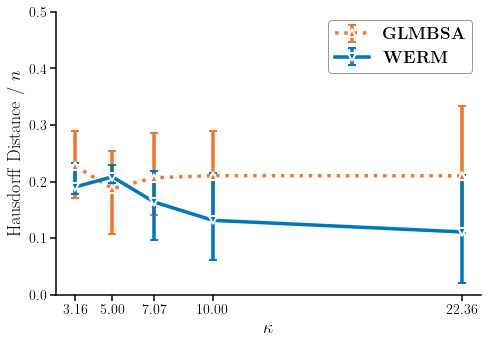

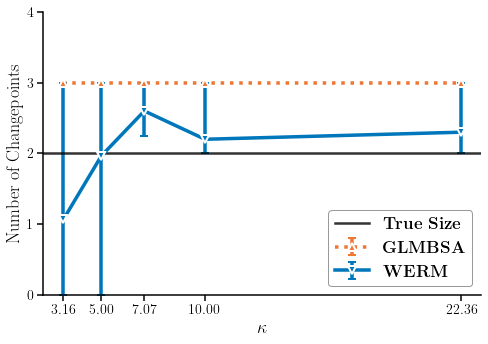

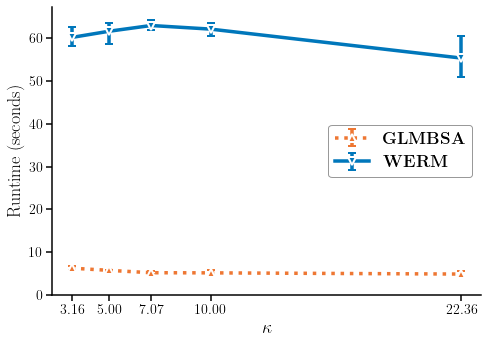


--- Plotting Box Plots ---


/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


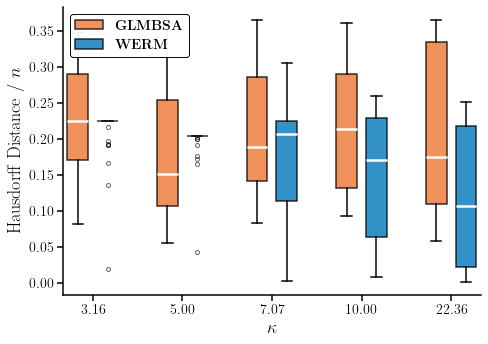

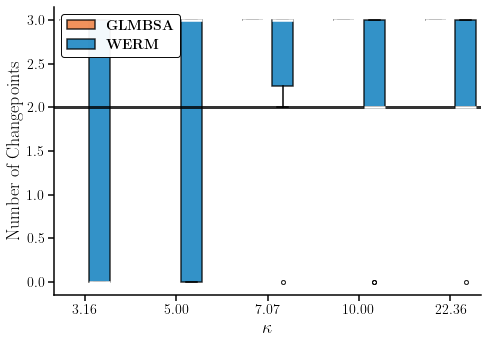

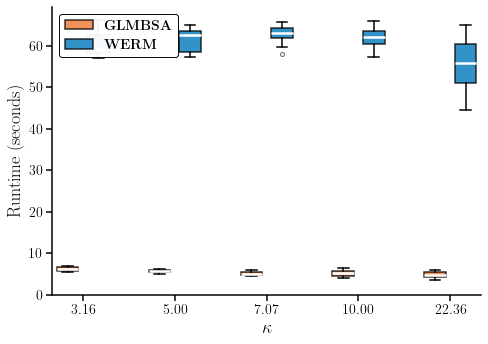


--- Plotting Changepoint Histograms ---


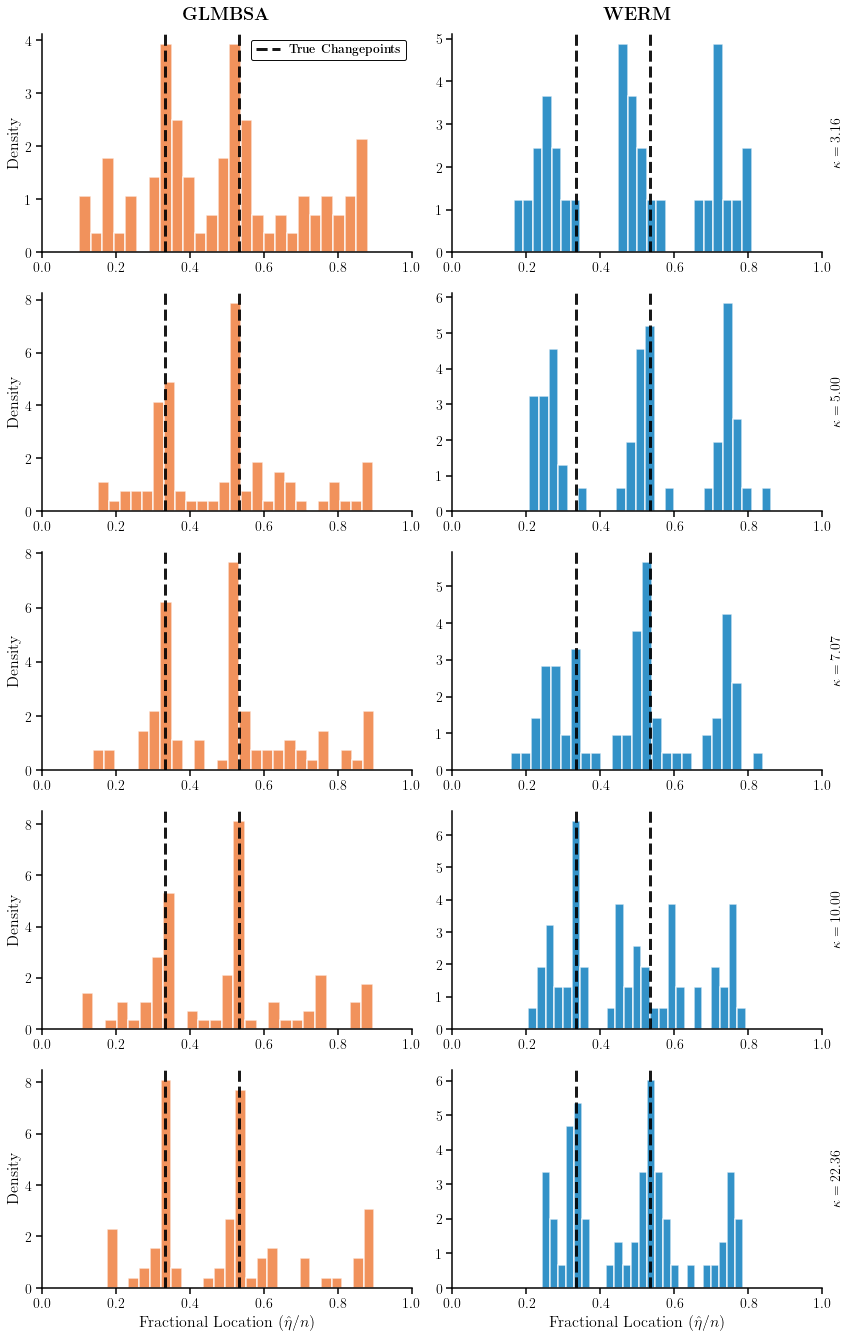

Publication-ready plotting completed in 3.52 seconds


In [9]:
import sys
import numpy as np
import time
import matplotlib
import gc
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import pickle
import os

# Ensure the 'figures' directory exists
FIGURES_DIR = 'figures'
if not os.path.exists(FIGURES_DIR):
    os.makedirs(FIGURES_DIR)

# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except Exception:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': True,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

try:
    # A dummy logger function to prevent NameError if main_logger is not defined
    def dummy_logger_info(message):
        print(message)
    main_logger = type('Logger', (object,), {'info': staticmethod(dummy_logger_info)})()
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']
PAL = TOL_VIBRANT

print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data ---
# This filename needs to match your saved results
filename_to_load = 'results/M3b_GLMBSA_WERM-CV_results_p200_L4_fixeddelta3.0_noisestd0.7745966692414834_kappa_100_316_500_707_1000_2236.pkl'
try:
    with open(filename_to_load, 'rb') as f:
        data = pickle.load(f)
    results = data['results']
    params = data['params']
    p = params['p']
    L = params['L']
    noise_std = params['noise_std']
    kappa_list = params['kappa_list']
    fractional_chgpt_locations = params['fractional_chgpt_locations']
    fixed_delta = params['fixed_delta']
    n_jobs = params['n_jobs']
    methods_to_evaluate = params['methods_evaluated']
    random_seed = params.get('random_seed', None) # Get random_seed if available

    # Ensure colors are assigned from the palette in order for loaded methods
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]
    print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")
    # Change the method name from 'WERM-CV' to 'WERM'
    for method in methods_to_evaluate:
        if method['name'] == 'WERM-CV':
            method['label'] = r'\textbf{WERM}'

    method_names_list = [method['name'] for method in methods_to_evaluate]

except FileNotFoundError:
    print(f"Error: Results file '{filename_to_load}' not found. Please ensure your results are saved.")
    print("For demonstration, creating dummy data.")
    # Create dummy data for demonstration if file not found
    p = 200
    L = 4
    noise_std = 0.7745966692414834
    kappa_list = np.array([1, 2, 3, 4, 5]) # Example kappas
    fractional_chgpt_locations = np.array([0.2, 0.4, 0.6, 0.8])
    num_trials = 10
    n_jobs = 1
    methods_to_evaluate = [
        {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'marker': 'o', 'linestyle': '-'},
        {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'marker': 's', 'linestyle': '--'},
    ]
    method_names_list = [method['name'] for method in methods_to_evaluate]

    # Assign colors from palette
    for i, method_obj in enumerate(methods_to_evaluate):
        method_obj['color'] = PAL[i % len(PAL)]

    results = {}
    for metric in ['haus', 'size', 'runtime', 'chgpts']:
        for method_config in methods_to_evaluate:
            method_name = method_config['name']
            key = f'{metric}_{method_name}'
            if metric == 'chgpts':
                results[key] = []
                for kappa_idx, kappa_val in enumerate(kappa_list):
                    n_for_kappa = int(kappa_val * p)
                    for _ in range(num_trials):
                        num_chgpts_detected = np.random.randint(L - 1, L + 2)
                        # Fix for histogram: Ensure dummy changepoints span 0-1 range
                        dummy_chgpts_fractional = np.random.rand(num_chgpts_detected)
                        # Scale to actual indices (0 to n_for_kappa) for storage
                        results[key].append((kappa_idx, dummy_chgpts_fractional * n_for_kappa))
            else:
                results[key] = np.random.rand(len(kappa_list), num_trials)
                if metric == 'size':
                    results[key] = np.round(results[key] * (L + 2)).astype(int)
                elif metric == 'runtime':
                    results[key] = results[key] * 10
                elif metric == 'haus':
                    results[key] = results[key] * 0.2 + 0.05
    random_seed = 42 # Set dummy seed

print("Data loaded/dummy data created for plotting.")

# Filter kappa_list for plotting from kappa = 1.5 and onwards
kappa_list = np.array(kappa_list) # Ensure it's a numpy array for easy filtering
kappa_start_index = np.where(kappa_list >= 1.5)[0]
if len(kappa_start_index) > 0:
    kappa_start_index = kappa_start_index[0]
else: # If no kappa >= 1.5, use the whole list or handle as an error
    kappa_start_index = 0
    print("Warning: No kappa values >= 1.5 found. Using all available kappa values for filtering.")

kappa_list_filtered = kappa_list[kappa_start_index:]

# Filter results based on the new kappa_list for line plots and all box plots
results_filtered = {}
for key, value in results.items():
    if key.startswith(('haus_', 'size_', 'runtime_')):
        if value.shape[0] > kappa_start_index:
            results_filtered[key] = value[kappa_start_index:, :]
        else:
            results_filtered[key] = np.empty((0, value.shape[1]))

print(f"DEBUG: Original kappa_list: {kappa_list}")
print(f"DEBUG: Filtered kappa_list (>= 1.5): {kappa_list_filtered}")
print(f"DEBUG: Method names available: {method_names_list}")
print(f"DEBUG: First few haus results (filtered): {results_filtered.get('haus_GLMBSA', 'Not available')[:2]}") # Changed to GLMBSA for consistency with example filename

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Asymmetric Error Bars Plotting Functions (Separated) ---

def plot_location_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'haus_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Hausdorff) for current kappa_list. Skipping plot for this metric.")
            continue
        data = np.where(np.isinf(data), np.nan, data)
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_asymmetric_errors.pgf"))
    plt.show()

def plot_size_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'size_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Size) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L))
    ax.set_yticks(np.arange(0, L + 1, step=1).astype(int))
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_asymmetric_errors.pgf"))
    plt.show()

def plot_runtime_asymmetric_errors(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime}', fontsize=18, pad=15) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = current_results.get(f'runtime_{method_name}')
        if data is None or data.size == 0 or np.all(np.isnan(data)):
            # main_logger.warning(f"No successful trials for {method_name} (Runtime) for current kappa_list. Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(current_kappa_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_xticks(current_kappa_list)
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.legend(loc='best', prop={'size': 17}, fancybox = True, framealpha = 0.4)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_asymmetric_errors.pgf"))
    plt.show()

# --- Box Plotting Functions (Separated) ---

def plot_location_boxplots(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Location Error: Distribution Comparison}', fontsize=18, y=0.98) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    methods = [method['name'] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    for kappa_idx, kappa in enumerate(current_kappa_list):
        box_data = []
        box_positions = []
        box_colors = []
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f'haus_{method_name}')
            if data is None or data.shape[0] <= kappa_idx:
                # main_logger.warning(f"No data for {method_name} for kappa {kappa:.2f} (Hausdorff). Skipping box plot for this point.")
                continue
            
            valid_data = data[kappa_idx, :][~np.isnan(data[kappa_idx, :])]
            if len(valid_data) > 0:
                box_data.append(valid_data)
                box_positions.append(kappa_idx * spacing + method_idx)
                box_colors.append(plot_colors[method_idx])
            else:
                main_logger.warning(f"No valid data for {method_name} for kappa {kappa:.2f} (Hausdorff). Skipping box plot for this point.")

        if len(box_data) > 0:
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')

    kappa_positions = [i * spacing + (len(methods) - 1) / 2 for i in range(len(current_kappa_list))]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels([f'{k:.2f}' for k in current_kappa_list])
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)

    legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                     alpha=0.8, edgecolor='black',
                                     linewidth=1.5, label=plot_labels[i])
                       for i in range(len(methods))]
    ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
              frameon=True, edgecolor='black', framealpha=0.95)

    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_boxplots.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_location_boxplots.pgf"))
    plt.show()

def plot_size_boxplots(current_kappa_list, current_results, methods_to_evaluate, L, fractional_chgpt_locations, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Changepoint Set Size: Distribution Comparison}', fontsize=18, y=0.98) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    methods = [method['name'] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    for kappa_idx, kappa in enumerate(current_kappa_list):
        box_data = []
        box_positions = []
        box_colors = []
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f'size_{method_name}')
            if data is None or data.shape[0] <= kappa_idx:
                # main_logger.warning(f"No data for {method_name} for kappa {kappa:.2f} (Size). Skipping box plot for this point.")
                continue
            
            valid_data = data[kappa_idx, :][~np.isnan(data[kappa_idx, :])]
            if len(valid_data) > 0:
                box_data.append(valid_data)
                box_positions.append(kappa_idx * spacing + method_idx)
                box_colors.append(plot_colors[method_idx])
            else:
                main_logger.warning(f"No valid data for {method_name} for kappa {kappa:.2f} (Size). Skipping box plot for this point.")

        if len(box_data) > 0:
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')

    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
    
    kappa_positions = [i * spacing + (len(methods) - 1) / 2 for i in range(len(current_kappa_list))]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels([f'{k:.2f}' for k in current_kappa_list])
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)

    legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                     alpha=0.8, edgecolor='black',
                                     linewidth=1.5, label=plot_labels[i])
                       for i in range(len(methods))]
    ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
              frameon=True, edgecolor='black', framealpha=0.95)

    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_boxplots.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_size_boxplots.pgf"))
    plt.show()

def plot_runtime_boxplots(current_kappa_list, current_results, methods_to_evaluate, filename_base):
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    # ax.set_title(r'\textbf{Method Runtime: Distribution Comparison}', fontsize=18, y=0.98) # Title removed

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    methods = [method['name'] for method in methods_to_evaluate]

    spacing = len(methods) + 1
    for kappa_idx, kappa in enumerate(current_kappa_list):
        box_data = []
        box_positions = []
        box_colors = []
        for method_idx, method_name in enumerate(methods):
            data = current_results.get(f'runtime_{method_name}')
            if data is None or data.shape[0] <= kappa_idx:
                main_logger.warning(f"No data for {method_name} for kappa {kappa:.2f} (Runtime). Skipping box plot for this point.")
                continue
            
            valid_data = data[kappa_idx, :][~np.isnan(data[kappa_idx, :])]
            if len(valid_data) > 0:
                box_data.append(valid_data)
                box_positions.append(kappa_idx * spacing + method_idx)
                box_colors.append(plot_colors[method_idx])
            else:
                main_logger.warning(f"No valid data for {method_name} for kappa {kappa:.2f} (Runtime). Skipping box plot for this point.")

        if len(box_data) > 0:
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')

    ax.set_ylim(bottom=0)
    kappa_positions = [i * spacing + (len(methods) - 1) / 2 for i in range(len(current_kappa_list))]
    ax.set_xticks(kappa_positions)
    ax.set_xticklabels([f'{k:.2f}' for k in current_kappa_list])
    ax.set_xlabel(r'$\kappa$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)

    legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                     alpha=0.8, edgecolor='black',
                                     linewidth=1.5, label=plot_labels[i])
                       for i in range(len(methods))]
    ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
              frameon=True, edgecolor='black', framealpha=0.95)

    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_boxplots.pdf"))
    plt.savefig(os.path.join(FIGURES_DIR, f"{filename_base}_runtime_boxplots.pgf"))
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(original_results, original_kappa_list, fractional_chgpt_locations, methods_to_plot_names, p):
    """
    Publication-ready changepoint location histograms.
    """
    
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_kappas_idx = [i for i, k in enumerate(original_kappa_list) if k >= 1.5]
    selected_kappas = [original_kappa_list[i] for i in selected_kappas_idx]
    
    if not methods_to_plot_names:
        print("Warning: No valid methods found for plotting histograms. Check 'methods_to_plot_names'.")
        return
    if not selected_kappas:
        print("Warning: No valid kappa values found (>= 1.5) for plotting histograms.")
        return

    fig, axes = plt.subplots(len(selected_kappas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_kappas)))

    if len(selected_kappas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_kappas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    # fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}', fontsize=20, y=0.98) # Title removed

    for row, (original_kappa_idx, kappa) in enumerate(zip(selected_kappas_idx, selected_kappas)):
        n = int(fixed_delta * p) # Calculate n based on kappa and p
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            chgpts_data_for_method = original_results.get(f'chgpts_{method_name}', [])
            
            for stored_kappa_idx, chgpts_list_for_trial in chgpts_data_for_method:
                if stored_kappa_idx == original_kappa_idx:
                    if isinstance(chgpts_list_for_trial, list):
                        for chgpts_arr in chgpts_list_for_trial:
                            if chgpts_arr is not None and len(chgpts_arr) > 0 and not (np.isscalar(chgpts_arr) and np.isnan(chgpts_arr)):
                                valid_chgpts = np.array(chgpts_arr)[np.array(chgpts_arr) != -1]
                                for chgpt in valid_chgpts:
                                    # Normalize by n to get fractional location [0, 1]
                                    fractional_chgpt = chgpt / n
                                    all_chgpts.append(fractional_chgpt)
                    elif chgpts_list_for_trial is not None and len(chgpts_list_for_trial) > 0 and not (np.isscalar(chgpts_list_for_trial) and np.isnan(chgpts_list_for_trial)):
                        valid_chgpts = np.array(chgpts_list_for_trial)[np.array(chgpts_list_for_trial) != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                # if len(all_chgpts) > 8:
                #     kde = gaussian_kde(all_chgpts)
                #     x_range = np.linspace(0, 1, 200)
                #     kde_values = kde(x_range)
                #     ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                #             alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            # True changepoints are already fractional
            for i_true, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', linewidth=3,
                           alpha=0.9, zorder=10,
                           label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1) # Ensure x-axis always spans 0 to 1 for fractional locations

            if row == len(selected_kappas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$\kappa = {kappa:.2f}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            if row == 0 and col == 0 and (len(all_chgpts) > 0 or fractional_chgpt_locations):
                handles, labels = ax.get_legend_handles_labels()
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                 edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    # Construct filename for histograms
    kappa_values_str = '_'.join(map(lambda x: str(int(x*100)), selected_kappas))
    methods_str = '_'.join(methods_to_plot_names)
    histogram_filename = f"histograms_{methods_str}_k{kappa_values_str}.pdf"
    plt.savefig(os.path.join(FIGURES_DIR, histogram_filename))
    plt.savefig(os.path.join(FIGURES_DIR, histogram_filename.replace('.pdf', '.pgf')))
    plt.show()


# Get a base filename for saving figures based on the loaded data's properties
# This uses the original filename from which data was loaded to create a consistent naming convention
filename_base_for_plots = os.path.basename(filename_to_load).replace('.pkl', '')
print(f"Base filename for saving plots: {filename_base_for_plots}")

# --- Execute plotting functions ---
print("\n--- Plotting Asymmetric Error Bars ---")
plot_location_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_size_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_asymmetric_errors(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Box Plots ---")
plot_location_boxplots(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)
plot_size_boxplots(kappa_list_filtered, results_filtered, methods_to_evaluate, L, fractional_chgpt_locations, filename_base_for_plots)
plot_runtime_boxplots(kappa_list_filtered, results_filtered, methods_to_evaluate, filename_base_for_plots)

print("\n--- Plotting Changepoint Histograms ---")
plot_changepoint_histograms_publication(results, kappa_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list, p=p)

plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# M3c: unknown num chgpt with BIC

In [ ]:
from WERM.signal_priors import SparseGaussianSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/M1a_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)

    progress_handler = logging.FileHandler('logs/M1a_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, delta_list, num_trials, logger):
        self.total_tasks = total_tasks
        self.delta_list = delta_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.delta_progress = {i: 0 for i in range(len(delta_list))}

    def update(self, delta_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.delta_progress[delta_idx] += 1
        if self.completed_tasks % max(1, self.total_tasks // 5) == 0 or self.completed_tasks == 1:
            delta_status = []
            for i, delta in enumerate(self.delta_list):
                progress = self.delta_progress[i]
                delta_status.append(f"δ={delta:.1f}: {progress}/{self.num_trials}")
            self.logger.info("Delta progress: " + " | ".join(delta_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, noise_std, fractional_chgpt_locations, M, gamma_candidates, method_configs):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, δ, j = params
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for δ={δ:.1f} (delta_idx={i})")

    # --- Setup based on delta ---
    n = int(δ * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    κ = np.sqrt(2.0) # np.sqrt(15) originally
    α = 0.5
    σ_l_arr = κ * np.sqrt(δ) * np.ones(L)
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p)
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    ε = np.random.uniform(0, 1, size=(n, ))



    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = np.array(jax.vmap(WERM.model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε))
    # y_standardized = y
    # print(f"y std: {np.std(y_standardized):.4f}, mean: {np.mean(y_standardized):.4f}")
    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators for all configured methods ---
    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    for method_name, method_func_info in method_configs.items():
        try:
            print(f"Running {method_name} on params: ", params)
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'GLMBSA':
                # cp = np.asarray(WERM.comparison.glm_bsa(X, y_standardized, delta = 0.1, kmax=len(fractional_chgpt_locations), is_exact=True))
                delta_fraction = 1/5
                cp = np.array(WERM.comparison.glm_bsa2(X_scaled, y.reshape((n, 1)), 
                                                       kmax=L-2, c1=0.18, 
                                                       m1 = None, delta = delta_fraction, exact=False))
                # Convert change points to 0-based indices, they are originally 1-based
                cp = cp - 1 # Convert to 0-based indexing
                # Remove endpoints
                cp = cp[(cp > 0) & (cp < n-1)] # Remove endpoints
                print("BSA cp: ", cp)
            elif method_name == 'WERM-CV':
                delta_fraction = 1/5
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                # Run cross-validation to find the best regularisation penalty parameter
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""

                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_
                    )

                # Perform cross-validation to find the best gamma
                # best_l1_reg, best_model_output = WERM.estimators.chgpt_k_fold_cv(
                #     f=WERM_l1_reg_paramCV,
                #     X=X,
                #     y=y,
                #     gamma_candidates=[1e-4, 1e-3, 1e-2],
                #     M_scorer=M_scorer,
                #     P_scorer=None,
                #     k=2,
                #     n_jobs=1
                # )

                # Fit OLS via least squares
                # beta_hat, _, _, _ = np.linalg.lstsq(X_scaled, y, rcond=None)

                # Compute residuals and estimate sigma
                # residuals = y - X_scaled.dot(beta_hat)
                # Unbiased estimator of sigma
                # sigma_hat = np.sqrt(np.sum(residuals**2) / (n - p - 1))
                # sigma_hat = np.median(np.abs(residuals - np.median(residuals))) / 0.6745 # More robust estimate of scale
                # sigma_hat=noise_std # Use the provided noise_std directly

                # Universal lambda
                # lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) + np.log(2*p)/n
                lambda_hat = 1 * np.sqrt(2 * np.log(p) / n) 

                # λ = c1 * ( np.sqrt(2 * np.log(2*p) / n) + np.log(2*p) / n


                # Best setting is κ=1.0, C=10, lambda_hat the shorter version
                # best_l1_reg = 3.25e-3
                C=10
                # # C=16
                best_l1_reg = C * n * lambda_hat
                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                # cp = WERM.estimators.weighted_erm(
                #     X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0.0,
                #     L_is_upper_bound=False, return_B_hat=False,
                #     brute_force=True, P_func=P_func
                # )
                gamma =1.0
                candidate_chgpts, fit_scores, penalty_scores=  WERM.estimators.weighted_erm_extended(X, y,M, L, 
                                                                                                     Delta_n(n), gamma, 
                                                                                                     brute_force=False, 
                                                                                                     P_func=P_func)
                candidate_scores = np.array(fit_scores) + gamma * np.array(penalty_scores)
                best_idx = np.argmin(candidate_scores)
                cp= candidate_chgpts[best_idx]
            elif method_name == 'WERM-unp':
                # Placeholder for WERM-unp method
                # This calls WERM.estimators.weighted_erm with P_func=None (no penalty)
                delta_fraction = 1/20
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                # gamma_candidates = np.array([1e-1, 1e-0, 1e1])
                # best_gamma, cp = WERM.estimators.weighted_erm_extended_penalizedCV(
                #     X, y, M, L, 
                #     Delta_n(n), gamma_candidates=gamma_candidates,
                #     brute_force=False, M_scorer=M_scorer,
                #     P_scorer=None, num_folds=2, n_jobs=2
                # )
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta_n(n), gamma=0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=True, 
                )
            elif method_name == 'WERM-fixed':
                # Placeholder for WERM-fixed method (e.g., with a fixed gamma)
                # This calls WERM.estimators.weighted_erm with a fixed penalty
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )

            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time

            # Handle Hausdorff distance calculation based on the method
            if method_name == 'DCDP' or method_name == 'DPDU': # DCDP and DPDU use closest_point_distance since they don't return a fixed number of changepoints
                if len(cp) > 0:
                    trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.closest_point_distance(cp, true_chgpts)
                else:
                    trial_results[f'haus_{method_name}'] = np.nan
            else: # Other methods use hausdorff
                trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp, true_chgpts)

            trial_results[f'size_{method_name}'] = len(cp[cp != -1])
            trial_results[f'chgpts_{method_name}'] = cp.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for δ={δ:.1f}: {method_name} failed with error: {e}")
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for δ={δ:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting Changepoint Detection Simulation with flexible methods and enhanced logging")
main_logger.info("=" * 60)

# Simulation Parameters
p = 200
L = 4
noise_std = np.sqrt(0.6) # Not used in logistic model
# δ_list = np.arange(1.0, 6.0, 1.0)
# δ_list = np.arange(1.0, 7.0, 1.0) #good
δ_list = np.arange(1.0, 6.0, 1.0)
num_trials = 15
# fractional_chgpt_locations = np.array([1/3, 8/15])
fractional_chgpt_locations = np.array([1/3,8/15])
# n_jobs = -1 # Use all available CPU cores
n_jobs = 45
# n_jobs = 1

# --- Set the covariance matrix for the features ---
r = 0.0
Sigma = np.eye(p)
for i_cov in range(p):
    for j_cov in range(p):
        if i_cov != j_cov:
            Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))

# def sample_corr(p, df=10, seed=None):
#     """Sample a random correlation matrix using the Haar measure."""
#     rng = np.random.default_rng(seed)
#     Q, _ = np.linalg.qr(rng.standard_normal((p, p)))            # Haar‐orthogonal
#     λ = rng.chisquare(df, size=p)                                # χ² eigenvalues
#     B = Q.T @ np.diag(λ) @ Q                                     # SPD matrix
#     D = np.sqrt(np.diag(B))
#     return B / np.outer(D, D)      

# Sigma = sample_corr(p, df=10, seed=random_seed)  # Sample a random correlation matrix

# --- Define Methods to be Evaluated ---
# This is the central list you can modify
methods_to_evaluate = [
    {'name': 'GLMBSA', 'label': r'\textbf{GLMBSA}', 'color': '#EE3377', 'marker': '^', 'linestyle': ':'},
    {'name': 'WERM-CV', 'label': r'\textbf{WERM-CV}', 'color': '#CC3311', 'marker': 'v', 'linestyle': '-'},
    # {'name': 'WERM-unp', 'label': r'\textbf{WERM-unp}', 'color': '#009988', 'marker': '<', 'linestyle': '--'},
    # {'name': 'WERM-fixed', 'label': r'\textbf{WERM-fixed}', 'color': '#BBBBBB', 'marker': '>', 'linestyle': '-.'},
]

# Removed the hardcoded check for exactly 4 methods.
# if len(methods_to_evaluate) != 4:
#     raise ValueError("The 'methods_to_evaluate' list must contain exactly 4 methods.")

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" noise_std: {noise_std}")
main_logger.info(f" δ_list: {δ_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(δ_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(δ_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': []
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(δ_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []


# Logistic loss function
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
M_scorer = M

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-4, 1, 8)

# --- Parallel Execution ---
tasks = [(i, δ, j) for i, δ in enumerate(δ_list) for j in range(num_trials)]
main_logger.info("=" * 60)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

single_trial_estimate = 30.0 * len(methods_to_evaluate)
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 60)

progress_tracker = ProgressTracker(len(tasks), δ_list, num_trials, main_logger)
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            noise_std=noise_std,
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates,
            method_configs=method_configs
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 60)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 60)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}")
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, δ_list[i]))

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta in enumerate(δ_list):
    main_logger.info(f"δ = {delta:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})
main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
               linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(δ_list, means, yerr=errors,
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(δ_list[::2])
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    # Updated ncol to dynamically adjust to the number of methods + True Size
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals}',
                     fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(δ_list, p10, p90, color=plot_colors[method_idx],
                            alpha=0.15, zorder=1)
            ax.plot(δ_list, means, color=plot_colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    # Updated ncol to dynamically adjust to the number of methods + True Size
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                     fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta:.1f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])
        ax.set_xticklabels([f'{d:.1f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                               for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                  frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_deltas_idx = list(range(len(δ_list)))
    selected_deltas = δ_list
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                        color=method_plotting_info[method_name]['color'],
                        density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                            alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                               alpha=0.9, zorder=10,
                               label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            # Only show legend on the first subplot where a KDE is plotted, or for true changepoints
            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate "True Changepoints" labels if present
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                        edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
# Pass the names of the methods for histogram plotting
plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
filename = f"results/M3c_{method_names_for_filename}_results_p{p}_L{L}_r{r}_noisestd{noise_std}_{'_'.join(map(str, map(int, δ_list)))}_.pkl"
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'noise_std': noise_std,
            'δ_list': δ_list,
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate # Save the method configurations
        }
    }, f)